# nf-core/rnaseq Reuse Experiment Analysis

Comparing resource and energy consumption across four experiment setups:
- **S1**: Two concurrent users, no reuse
- **S2_seq**: Two sequential users, full artifact reuse (resume)
- **S2**: Two concurrent users, shared genome index reuse
- **S3**: Two concurrent users, pod-service reuse

### Measurement rules:
- **S1, S2-seq, S2**: only `nf-*` task pods are counted (no service pods exist)
- **S3**: `nf-*` task pods + `featurecounts-service` + `stringtie-service`, but **ALL metrics windowed to pipeline execution time only** (first nf-* pod activity → last nf-* pod activity)


In [33]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

BASE_PATH = '/home/sm/experiments/data'

EXPERIMENTS = {
    'S1: No Reuse': 'Normal_nextflow_rnaseq_U2_baseline_2026_04_20_16_59_50_087c5c97/data',
    'S2-seq: Full Reuse': 'Normal_nextflow_rnaseq_U2_full_resume_2026_04_15_11_52_07_87980c68/data',
    'S2: Index Reuse': 'Normal_nextflow_rnaseq_U2_shared_index_2026_04_14_20_36_18_c55e127f/data',
    'S3: Pod-Service': 'Normal_nextflow_rnaseq_U2_podservice_2026_04_14_11_34_34_a5f0c363/data',
    'S3: delayed-pods-service' : 'Delayed_nextflow_rnaseq_U2_podservice_2026_04_13_22_11_39_19d00f6f/data',
}

S3_LABELS = {
    'S3: Pod-Service',
    'S3: delayed-pods-service'
}
SERVICE_POD_NAMES = ['featurecounts-service', 'stringtie-service']

COLORS = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9467bd']
EXP_COLORS = dict(zip(EXPERIMENTS.keys(), COLORS))

def find_csv(exp_dir, metric_name):
    for subdir in ['', 'data/']:
        path = os.path.join(BASE_PATH, exp_dir, subdir, f'{metric_name}.csv')
        if os.path.exists(path):
            return path
    matches = glob.glob(os.path.join(BASE_PATH, exp_dir, '**', f'{metric_name}.csv'), recursive=True)
    return matches[0] if matches else None

def load_metric(exp_dir, metric_name):
    path = find_csv(exp_dir, metric_name)
    if not path:
        return None
    try:
        df = pd.read_csv(path)
        for col in df.columns:
            if 'time' in col.lower():
                try:
                    df[col] = pd.to_datetime(df[col], utc=True, errors='coerce')
                except:
                    pass
        return df
    except:
        return None

def get_pod_col(df):
    for c in ['pod_name', 'pod', 'Pod']:
        if c in df.columns:
            return c
    return None

def get_val_col(df):
    for c in ['kepler_pod_cpu_power_joules_raw', 'value']:
        if c in df.columns:
            return c
    nums = df.select_dtypes(include=[np.number]).columns.tolist()
    return nums[-1] if nums else None

def get_ts_col(df):
    for c in df.columns:
        if 'time' in c.lower() and pd.api.types.is_datetime64_any_dtype(df[c]):
            return c
    return None

def get_pipeline_window(exp_dir, metric='kepler_pod_cpu_power_joules_raw'):
    df = load_metric(exp_dir, metric)
    if df is None:
        return None, None
    pod_col = get_pod_col(df)
    ts_col  = get_ts_col(df)
    if pod_col is None or ts_col is None:
        return None, None
    is_task = df[pod_col].astype(str).str.startswith('nf-')
    if not is_task.any():
        return None, None
    return df[is_task][ts_col].min(), df[is_task][ts_col].max()

    import re
    # Match: 2026_03_31_17_00_16
    hour_match = re.search(r'(\d{4})_(\d{2})_(\d{2})_(\d{2})_(\d{2})_(\d{2})', exp_dir)
    if hour_match:
        year, month, day, hour, minute, second = hour_match.groups()
        anchor = pd.Timestamp(f'{year}-{month}-{day}T{hour}:{minute}:{second}', tz='UTC')
        print(f'  Anchor from dir name: {anchor}')
        task_df = df[is_task &
                     (df[ts_col] >= anchor) &
                     (df[ts_col] <= anchor + pd.Timedelta(hours=3))]
        print(f'  nf-* pods in window: {len(task_df)}')
    else:
        print('  No timestamp found in dir name, using all nf-* pods')
        task_df = df[is_task]

    if task_df.empty:
        return None, None
    return task_df[ts_col].min(), task_df[ts_col].max()
# Cache the S3 pipeline window
#S3_WIN_START, S3_WIN_END = get_pipeline_window(EXPERIMENTS[S3_LABEL])
S3_WINDOWS = {
    label: get_pipeline_window(EXPERIMENTS[label])
    for label in S3_LABELS
}
print(f'S3 pipeline window: {S3_WIN_START} → {S3_WIN_END}')

def corrected_df(exp_dir, exp_label, metric):
    """
    Returns a filtered dataframe applying the measurement rules:
    - S1/S2-seq/S2: only nf-* task pods
    - S3: nf-* task pods + service pods, ALL windowed to pipeline execution time
    """
    df = load_metric(exp_dir, metric)
    if df is None or df.empty:
        return None

    val_col = get_val_col(df)
    pod_col = get_pod_col(df)
    ts_col  = get_ts_col(df)

    if val_col is None:
        return None

    df[val_col] = pd.to_numeric(df[val_col], errors='coerce').fillna(0)

    if pod_col is None:
        return df

    is_task = df[pod_col].astype(str).str.startswith('nf-')
    is_service = df[pod_col].astype(str).str.contains(
        '|'.join(SERVICE_POD_NAMES), case=False, na=False
    )

    # ✅ S3 experiments (both normal + delayed)
    if exp_label in S3_LABELS:
        keep = is_task | is_service
        df = df[keep].copy()

        win_start, win_end = S3_WINDOWS.get(exp_label, (None, None))

        if ts_col and win_start is not None:
            df = df[
                (df[ts_col] >= win_start) &
                (df[ts_col] <= win_end)
            ].copy()

    # ✅ S1 / S2 experiments
    else:
        df = df[is_task].copy()

    return df

def get_corrected_value(exp_dir, exp_label, metric, agg='sum', scale=1.0):
    df = corrected_df(exp_dir, exp_label, metric)
    if df is None or df.empty:
        return np.nan
    val_col = get_val_col(df)
    if val_col is None:
        return np.nan
    if agg == 'sum':
        return df[val_col].sum() * scale
    else:
        return df[val_col].mean() * scale

# Verify
print('\n=== Corrected Energy per Experiment ===')
for exp_label, exp_dir in EXPERIMENTS.items():
    val = get_corrected_value(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw')
    print(f'  {exp_label}: {val:.1f} J')


S3 pipeline window: 2026-04-14 09:35:54.102999926+00:00 → 2026-04-14 14:09:24.102999926+00:00

=== Corrected Energy per Experiment ===
  S1: No Reuse: 310464.0 J
  S2-seq: Full Reuse: 259034.3 J
  S2: Index Reuse: 615434.1 J
  S3: Pod-Service: 986369.7 J
  S3: delayed-pods-service: 683925.9 J


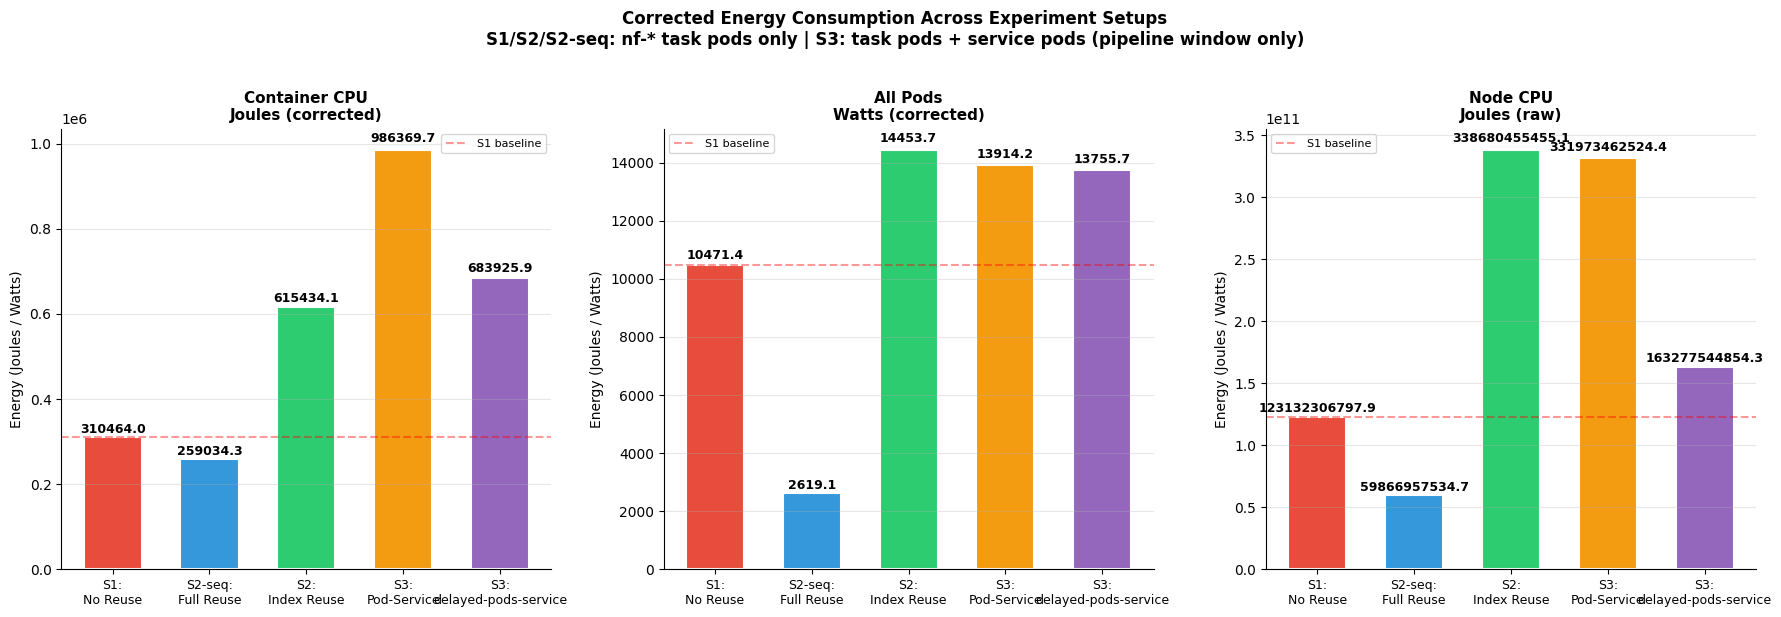

In [34]:
# ── Plot 1: Corrected Energy Comparison (3 Kepler metrics) ────────────

kepler_metrics = [
    'kepler_pod_cpu_power_joules_raw',
    'kepler_all_pod_cpu_power_watts',
    'kepler_node_cpu_power_raw',
]
kepler_labels = {
    'kepler_pod_cpu_power_joules_raw': 'Container CPU\nJoules (corrected)',
    'kepler_all_pod_cpu_power_watts':  'All Pods\nWatts (corrected)',
    'kepler_node_cpu_power_raw':       'Node CPU\nJoules (raw)',
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Corrected Energy Consumption Across Experiment Setups\n'
    'S1/S2/S2-seq: nf-* task pods only | S3: task pods + service pods (pipeline window only)',
    fontsize=12, fontweight='bold', y=1.02)

for ax, metric in zip(axes, kepler_metrics):
    values, labels, colors = [], [], []
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_corrected_value(exp_dir, exp_label, metric)
        values.append(val if not np.isnan(val) else 0)
        labels.append(exp_label.replace(': ', ':\n'))
        colors.append(EXP_COLORS[exp_label])

    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
        ax.legend(fontsize=8)
    ax.set_title(kepler_labels[metric], fontsize=11, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel('Energy (Joules / Watts)', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot1_energy_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


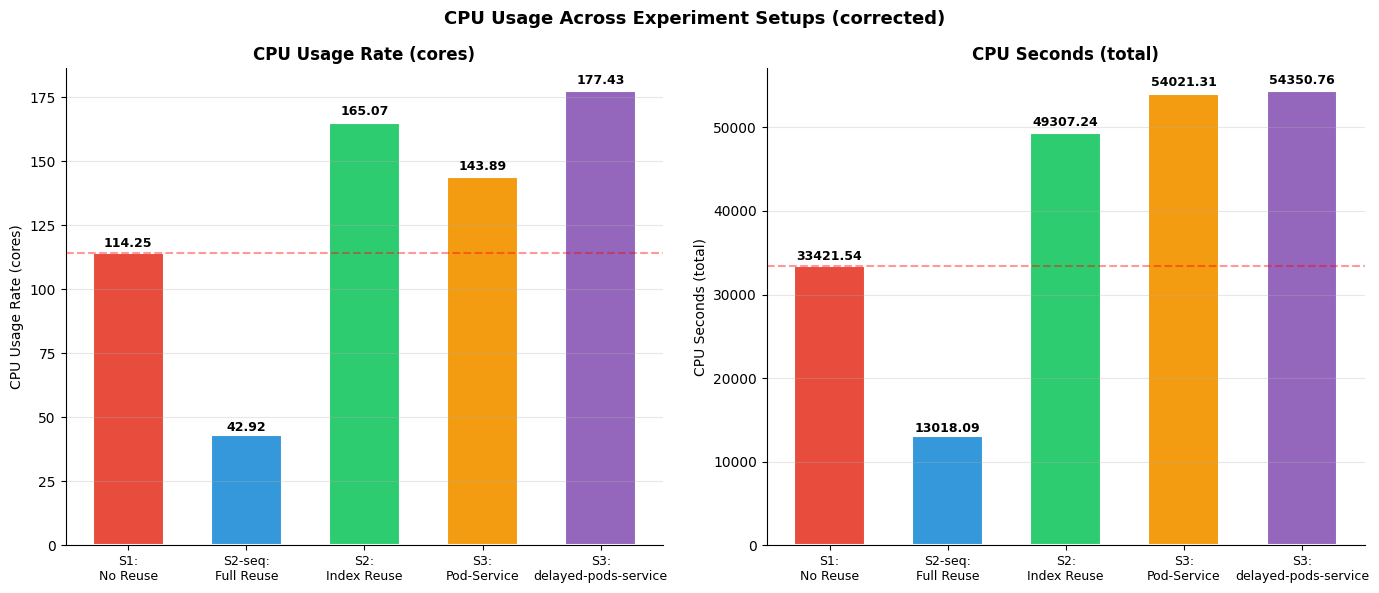

In [35]:
# ── Plot 2: CPU Usage (corrected) ─────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('CPU Usage Across Experiment Setups (corrected)', fontsize=13, fontweight='bold')

for ax, (metric, title) in zip(axes, [
    ('system_cpu_usage',     'CPU Usage Rate (cores)'),
    ('system_cpu_usage_raw', 'CPU Seconds (total)'),
]):
    values, labels, colors = [], [], []
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_corrected_value(exp_dir, exp_label, metric, 'sum')
        values.append(val if not np.isnan(val) else 0)
        labels.append(exp_label.replace(': ', ':\n'))
        colors.append(EXP_COLORS[exp_label])

    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
                   f'{val:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot2_cpu_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


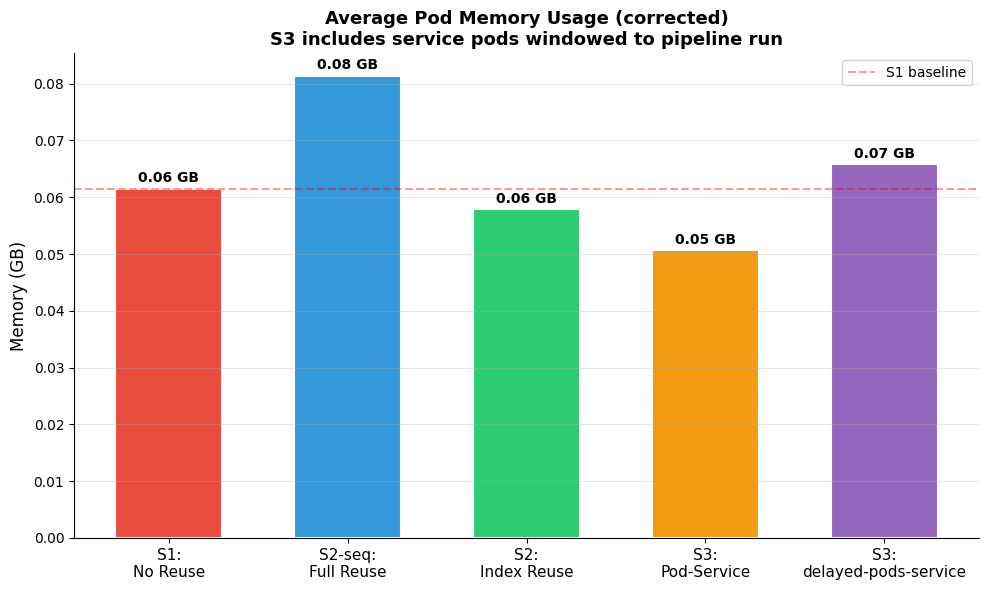

In [36]:
# ── Plot 3: Memory Usage (corrected) ──────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))
values, labels, colors = [], [], []
for exp_label, exp_dir in EXPERIMENTS.items():
    val = get_corrected_value(exp_dir, exp_label, 'pod_memory_usage', 'mean', 1/(1024**3))
    values.append(val if not np.isnan(val) else 0)
    labels.append(exp_label.replace(': ', ':\n'))
    colors.append(EXP_COLORS[exp_label])

bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
for bar, val in zip(bars, values):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
               f'{val:.2f} GB', ha='center', va='bottom', fontsize=10, fontweight='bold')
if values[0] > 0:
    ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
    ax.legend()
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Memory (GB)', fontsize=12)
ax.set_title('Average Pod Memory Usage (corrected)\n'
             'S3 includes service pods windowed to pipeline run', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('/tmp/plot3_memory_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


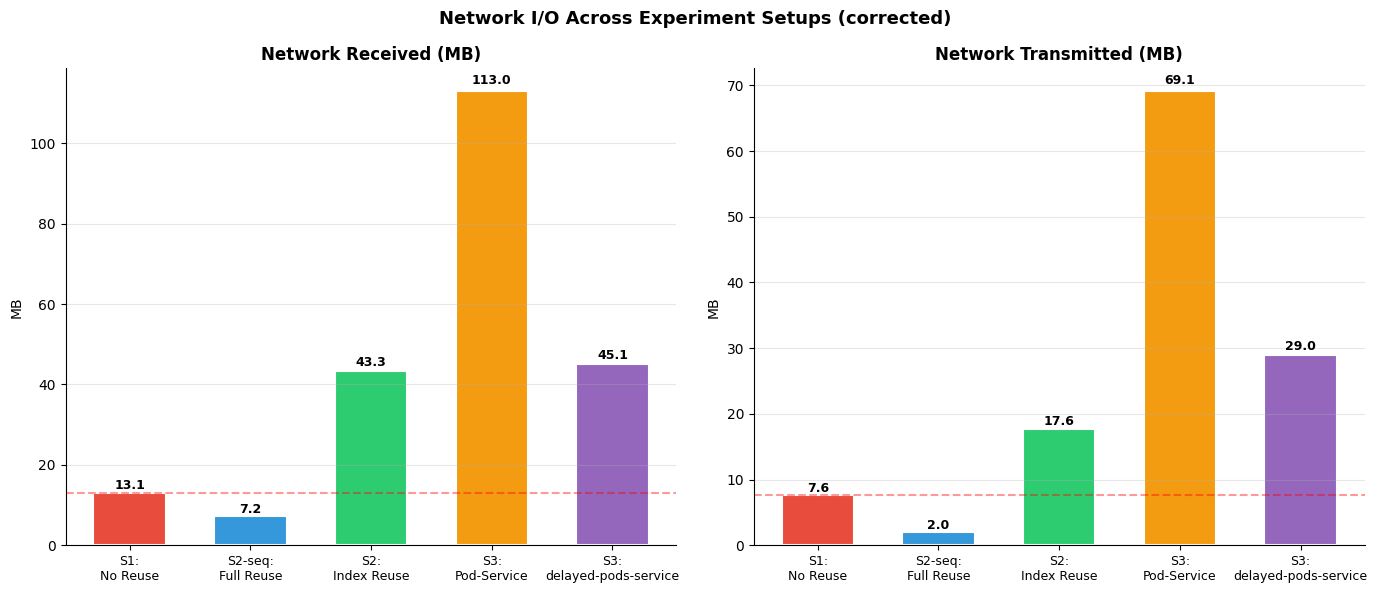

In [37]:
# ── Plot 4: Network I/O (corrected) ───────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Network I/O Across Experiment Setups (corrected)', fontsize=13, fontweight='bold')

for ax, (metric, title) in zip(axes, [
    ('pod_network_receive_bytes_raw',  'Network Received (MB)'),
    ('pod_network_transmit_bytes_raw', 'Network Transmitted (MB)'),
]):
    values, labels, colors = [], [], []
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_corrected_value(exp_dir, exp_label, metric, 'sum', 1/(1024**2))
        values.append(val if not np.isnan(val) else 0)
        labels.append(exp_label.replace(': ', ':\n'))
        colors.append(EXP_COLORS[exp_label])

    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel('MB', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot4_network_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


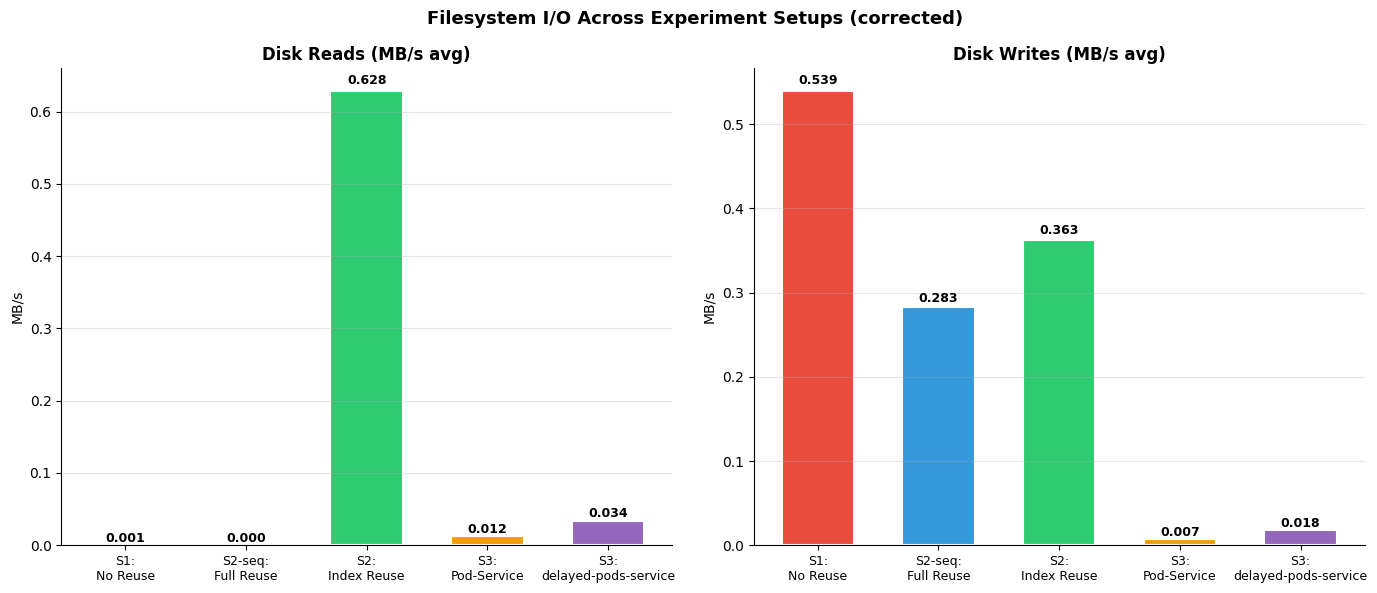

In [38]:
# ── Plot 5: Filesystem I/O (corrected) ────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Filesystem I/O Across Experiment Setups (corrected)', fontsize=13, fontweight='bold')

for ax, (metric, title) in zip(axes, [
    ('pod_fs_reads_bytes',  'Disk Reads (MB/s avg)'),
    ('pod_fs_write_bytes',  'Disk Writes (MB/s avg)'),
]):
    values, labels, colors = [], [], []
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_corrected_value(exp_dir, exp_label, metric, 'mean', 1/(1024**2))
        values.append(val if not np.isnan(val) else 0)
        labels.append(exp_label.replace(': ', ':\n'))
        colors.append(EXP_COLORS[exp_label])

    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
                   f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel('MB/s', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot5_filesystem_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


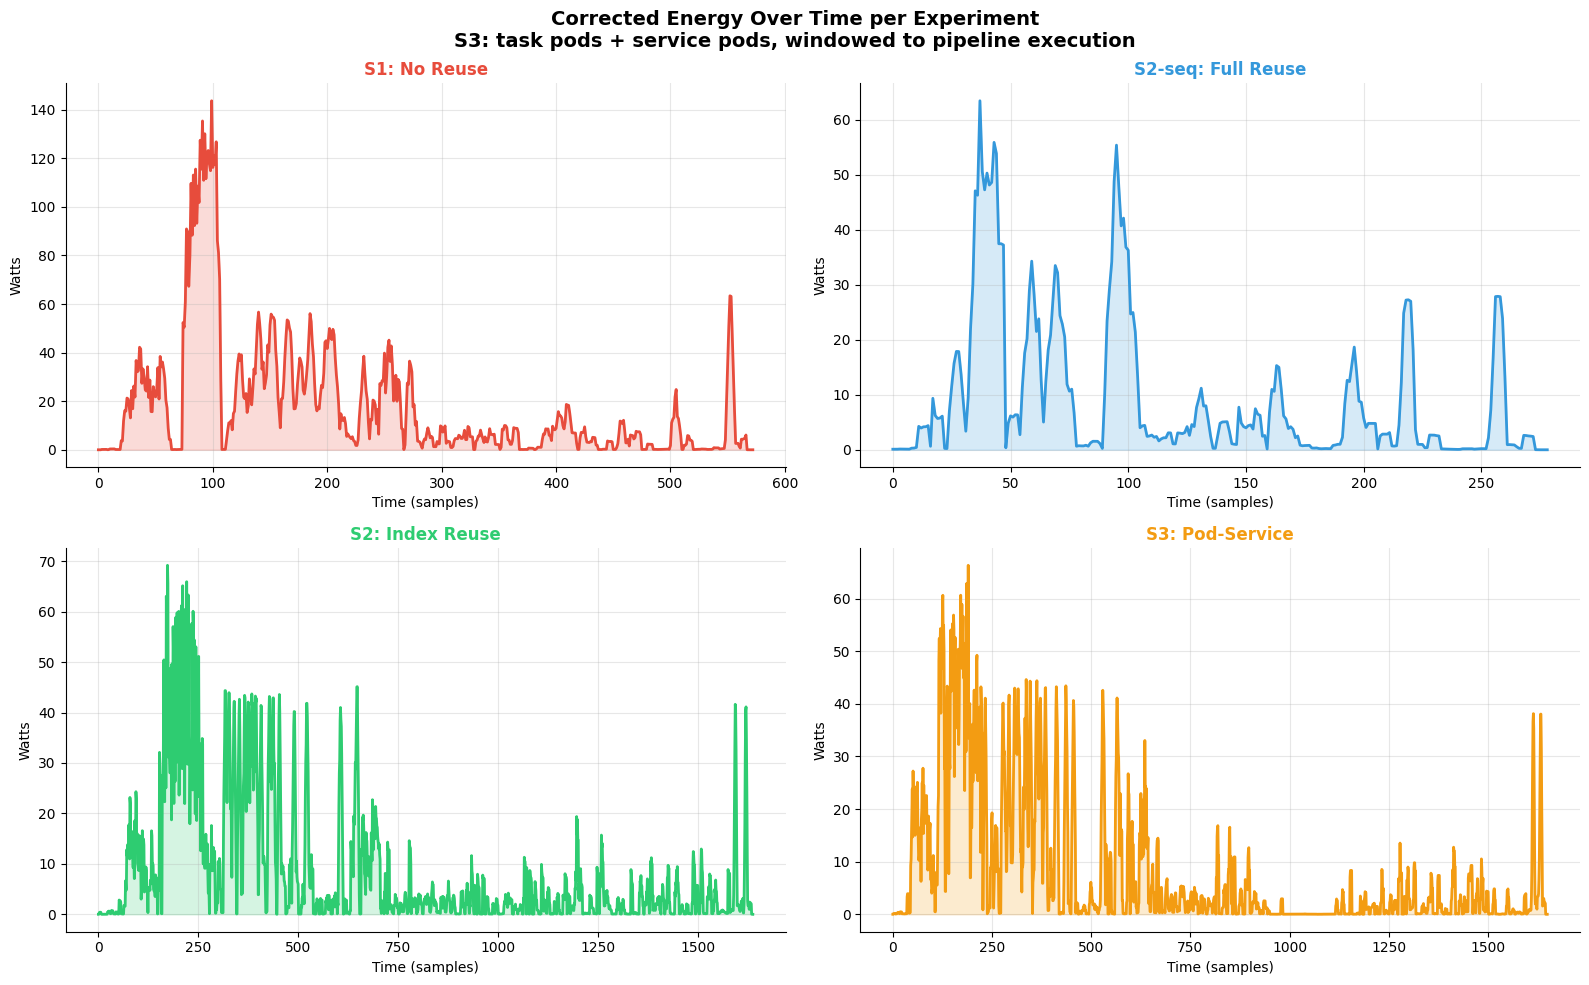

In [39]:
# ── Plot 6: Energy Over Time (corrected time series) ──────────────────

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Corrected Energy Over Time per Experiment\n'
             'S3: task pods + service pods, windowed to pipeline execution',
             fontsize=14, fontweight='bold')
axes_flat = axes.flatten()

for ax, (exp_label, exp_dir) in zip(axes_flat, EXPERIMENTS.items()):
    df = corrected_df(exp_dir, exp_label, 'kepler_all_pod_cpu_power_watts')
    if df is None or df.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(exp_label)
        continue

    val_col = get_val_col(df)
    ts_col  = get_ts_col(df)

    if val_col is None:
        ax.text(0.5, 0.5, 'No value col', ha='center', va='center', transform=ax.transAxes)
        continue

    if ts_col:
        ts = df.groupby(ts_col)[val_col].sum().reset_index().sort_values(ts_col)
        ax.plot(range(len(ts)), ts[val_col].values,
               color=EXP_COLORS[exp_label], linewidth=2)
        ax.fill_between(range(len(ts)), ts[val_col].values,
                       alpha=0.2, color=EXP_COLORS[exp_label])
    else:
        ax.plot(df[val_col].values, color=EXP_COLORS[exp_label], linewidth=2)

    ax.set_title(exp_label, fontsize=12, fontweight='bold', color=EXP_COLORS[exp_label])
    ax.set_ylabel('Watts', fontsize=10)
    ax.set_xlabel('Time (samples)', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot6_timeseries_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


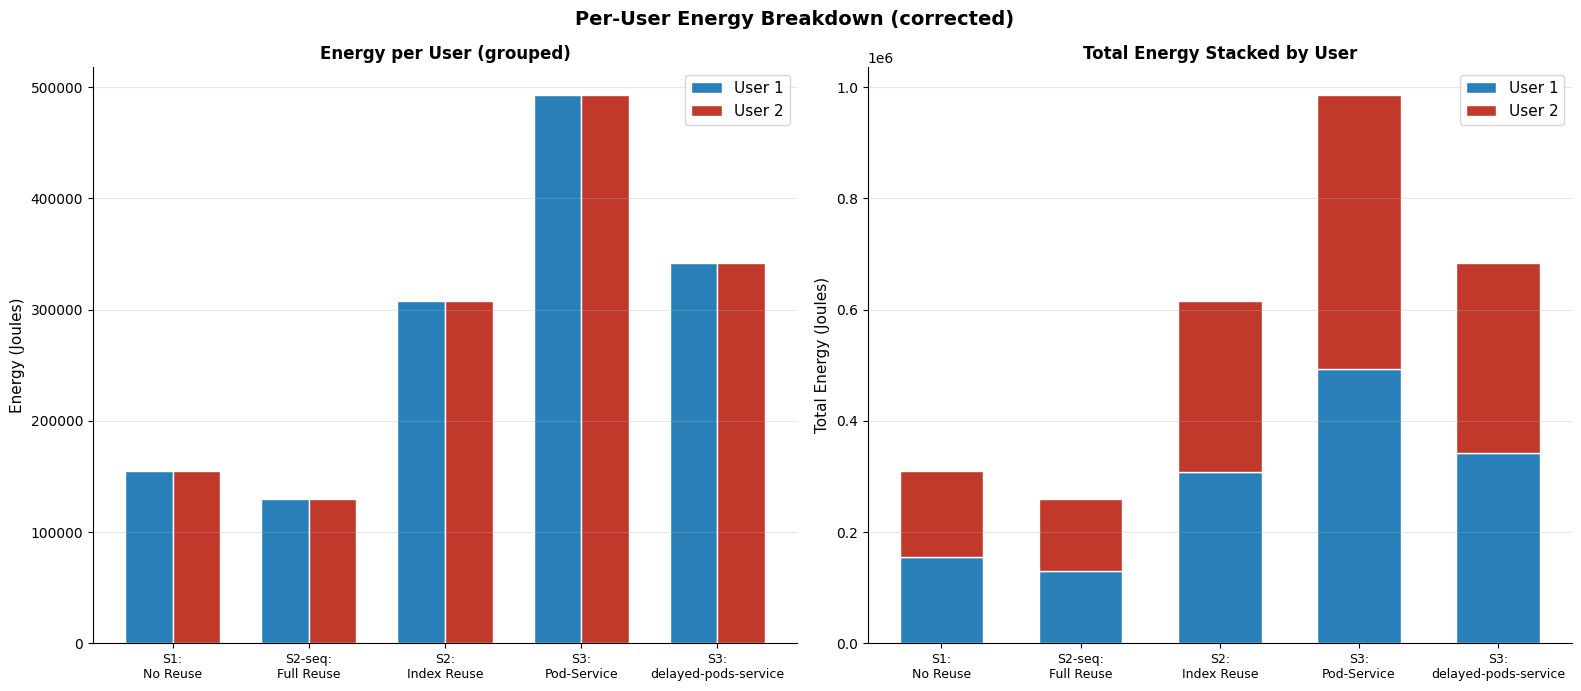

In [40]:
# ── Plot 7: Per-User Energy Breakdown (corrected) ─────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Per-User Energy Breakdown (corrected)', fontsize=14, fontweight='bold')

exp_names, u1_vals, u2_vals = [], [], []

for exp_label, exp_dir in EXPERIMENTS.items():
    df = corrected_df(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw_per_user')
    exp_names.append(exp_label.replace(': ', ':\n'))

    if df is not None and not df.empty:
        val_col  = get_val_col(df)
        user_col = next((c for c in df.columns if 'user' in c.lower() and 'label' in c.lower()), None)
        if val_col and user_col:
            df[val_col] = pd.to_numeric(df[val_col], errors='coerce').fillna(0)
            u1_vals.append(df[df[user_col]=='user1'][val_col].sum())
            u2_vals.append(df[df[user_col]=='user2'][val_col].sum())
        else:
            total = get_corrected_value(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw')
            u1_vals.append(total/2 if not np.isnan(total) else 0)
            u2_vals.append(total/2 if not np.isnan(total) else 0)
    else:
        total = get_corrected_value(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw')
        u1_vals.append(total/2 if not np.isnan(total) else 0)
        u2_vals.append(total/2 if not np.isnan(total) else 0)

x = np.arange(len(exp_names))
width = 0.35

ax = axes[0]
ax.bar(x - width/2, u1_vals, width, label='User 1', color='#2980b9', edgecolor='white')
ax.bar(x + width/2, u2_vals, width, label='User 2', color='#c0392b', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(exp_names, fontsize=9)
ax.set_ylabel('Energy (Joules)', fontsize=11)
ax.set_title('Energy per User (grouped)', fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax2 = axes[1]
ax2.bar(x, u1_vals, width=0.6, label='User 1', color='#2980b9', edgecolor='white')
ax2.bar(x, u2_vals, width=0.6, bottom=u1_vals, label='User 2', color='#c0392b', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(exp_names, fontsize=9)
ax2.set_ylabel('Total Energy (Joules)', fontsize=11)
ax2.set_title('Total Energy Stacked by User', fontsize=12, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot7_per_user_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


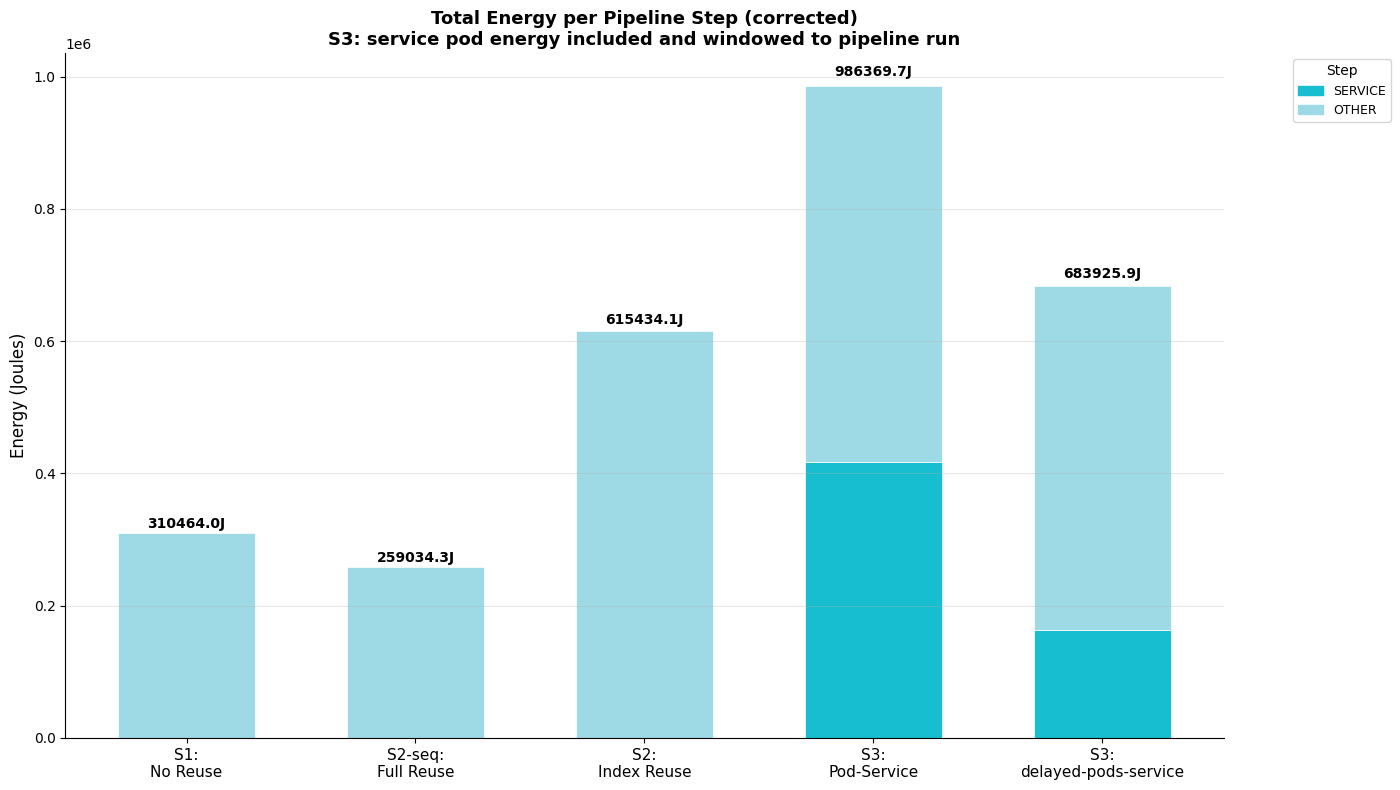

In [41]:
# ── Plot 8: Stacked Energy per Pipeline Step (corrected) ──────────────

PIPELINE_STEPS = ['PREPARE_GENOME','TRIMGALORE','FASTQC','BBMAP_BBSPLIT',
                  'STAR_ALIGN','SAMTOOLS','SALMON_QUANT','STRINGTIE',
                  'FEATURECOUNTS','DESEQ2','MULTIQC','SERVICE','OTHER']
step_colors = plt.cm.tab20(np.linspace(0, 1, len(PIPELINE_STEPS)))
step_color_map = dict(zip(PIPELINE_STEPS, step_colors))

def extract_step(pod_name):
    pod_upper = str(pod_name).upper()
    for step in ['FEATURECOUNTS-SERVICE','STRINGTIE-SERVICE']:
        if step in pod_upper:
            return 'SERVICE'
    for step in PIPELINE_STEPS[:-2]:  # exclude SERVICE and OTHER
        if step in pod_upper:
            return step
    return 'OTHER'

fig, ax = plt.subplots(figsize=(14, 8))
exp_labels_short = [e.replace(': ', ':\n') for e in EXPERIMENTS.keys()]
x = np.arange(len(exp_labels_short))
step_data = {step: [] for step in PIPELINE_STEPS}

for exp_label, exp_dir in EXPERIMENTS.items():
    df = corrected_df(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw')
    step_totals = {step: 0.0 for step in PIPELINE_STEPS}

    if df is not None and not df.empty:
        val_col = get_val_col(df)
        pod_col = get_pod_col(df)
        if val_col and pod_col:
            for _, row in df.iterrows():
                step = extract_step(row[pod_col])
                step_totals[step] += float(row[val_col])
        elif val_col:
            step_totals['OTHER'] = df[val_col].sum()

    for step in PIPELINE_STEPS:
        step_data[step].append(step_totals[step])

bottoms = np.zeros(len(exp_labels_short))
patches = []
for step in PIPELINE_STEPS:
    vals = np.array(step_data[step])
    if vals.sum() > 0:
        color = step_color_map[step]
        ax.bar(x, vals, width=0.6, bottom=bottoms, color=color, edgecolor='white', linewidth=0.5)
        bottoms += vals
        patches.append(mpatches.Patch(color=color, label=step))

for i, total in enumerate(bottoms):
    if total > 0:
        ax.text(i, total*1.01, f'{total:.1f}J', ha='center', va='bottom',
               fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(exp_labels_short, fontsize=11)
ax.set_ylabel('Energy (Joules)', fontsize=12)
ax.set_title('Total Energy per Pipeline Step (corrected)\n'
             'S3: service pod energy included and windowed to pipeline run',
             fontsize=13, fontweight='bold')
ax.legend(handles=patches, loc='upper right', bbox_to_anchor=(1.15,1), fontsize=9, title='Step')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('/tmp/plot8_stacked_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


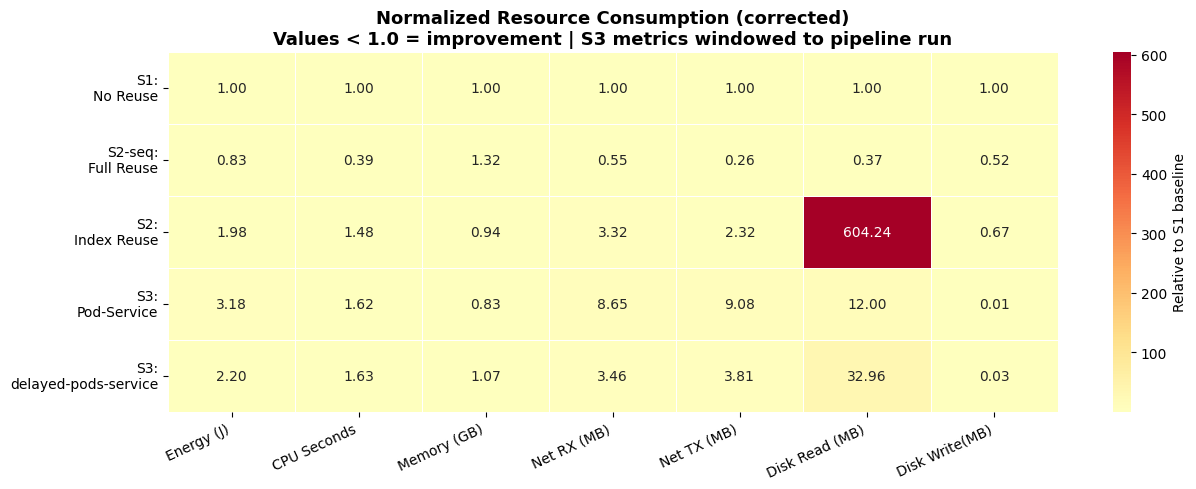

In [42]:
# ── Plot 9: Normalized Heatmap (corrected) ────────────────────────────

metrics_summary = {
    'Energy (J)':     ('kepler_pod_cpu_power_joules_raw', 'sum', 1),
    'CPU Seconds':    ('system_cpu_usage_raw',            'sum', 1),
    'Memory (GB)':    ('pod_memory_usage',                'mean', 1/(1024**3)),
    'Net RX (MB)':    ('pod_network_receive_bytes_raw',   'sum', 1/(1024**2)),
    'Net TX (MB)':    ('pod_network_transmit_bytes_raw',  'sum', 1/(1024**2)),
    'Disk Read (MB)': ('pod_fs_reads_bytes',              'mean', 1/(1024**2)),
    'Disk Write(MB)': ('pod_fs_write_bytes',              'mean', 1/(1024**2)),
}

summary_data = {}
for exp_label, exp_dir in EXPERIMENTS.items():
    row = {}
    for m_label, (metric, agg, scale) in metrics_summary.items():
        row[m_label] = get_corrected_value(exp_dir, exp_label, metric, agg, scale)
    summary_data[exp_label.replace(': ', ':\n')] = row

summary_df = pd.DataFrame(summary_data).T.fillna(0)
baseline = summary_df.iloc[0]
normalized = summary_df.div(baseline).replace([np.inf, -np.inf], np.nan).fillna(1.0)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(normalized, annot=True, fmt='.2f', cmap='RdYlGn_r',
           center=1.0, ax=ax, linewidths=0.5,
           cbar_kws={'label': 'Relative to S1 baseline'})
ax.set_title('Normalized Resource Consumption (corrected)\n'
             'Values < 1.0 = improvement | S3 metrics windowed to pipeline run',
             fontsize=13, fontweight='bold')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('/tmp/plot9_heatmap_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


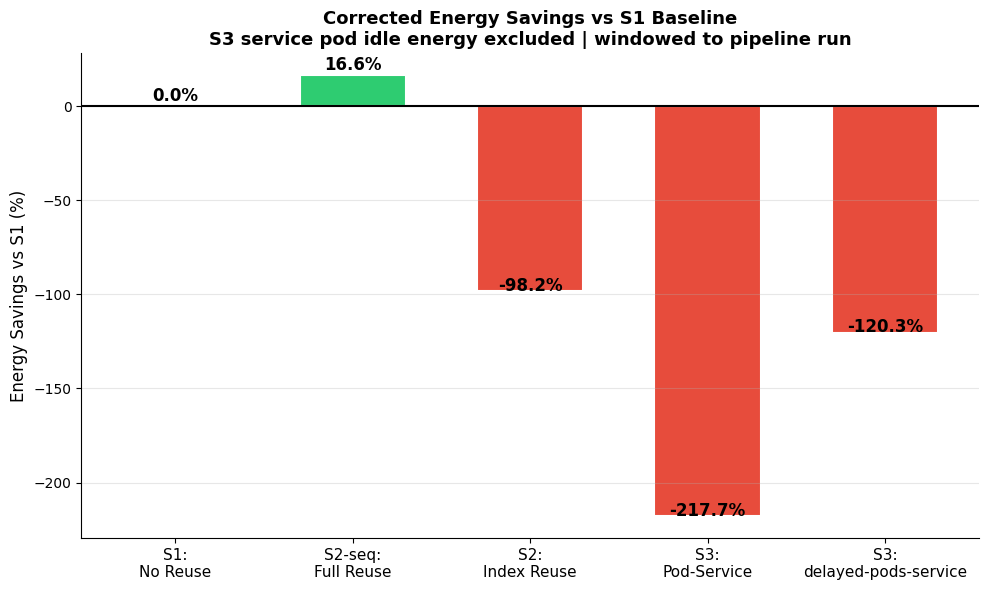

In [43]:
# ── Plot 10: Energy Savings (corrected) ───────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))
baseline_e = get_corrected_value(
    list(EXPERIMENTS.values())[0], list(EXPERIMENTS.keys())[0],
    'kepler_pod_cpu_power_joules_raw')

savings, labels, colors = [], [], []
for exp_label, exp_dir in EXPERIMENTS.items():
    val = get_corrected_value(exp_dir, exp_label, 'kepler_pod_cpu_power_joules_raw')
    pct = (1 - val/baseline_e)*100 if (not np.isnan(val) and baseline_e > 0) else 0
    savings.append(pct)
    labels.append(exp_label.replace(': ', ':\n'))
    colors.append('#e74c3c' if pct < 0 else '#2ecc71')

bars = ax.bar(range(len(labels)), savings, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
for bar, val in zip(bars, savings):
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., y + (0.5 if y >= 0 else -2),
           f'{val:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.axhline(y=0, color='black', linewidth=1.5)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Energy Savings vs S1 (%)', fontsize=12)
ax.set_title('Corrected Energy Savings vs S1 Baseline\n'
             'S3 service pod idle energy excluded | windowed to pipeline run',
             fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('/tmp/plot10_savings_corrected.png', dpi=150, bbox_inches='tight')
plt.show()


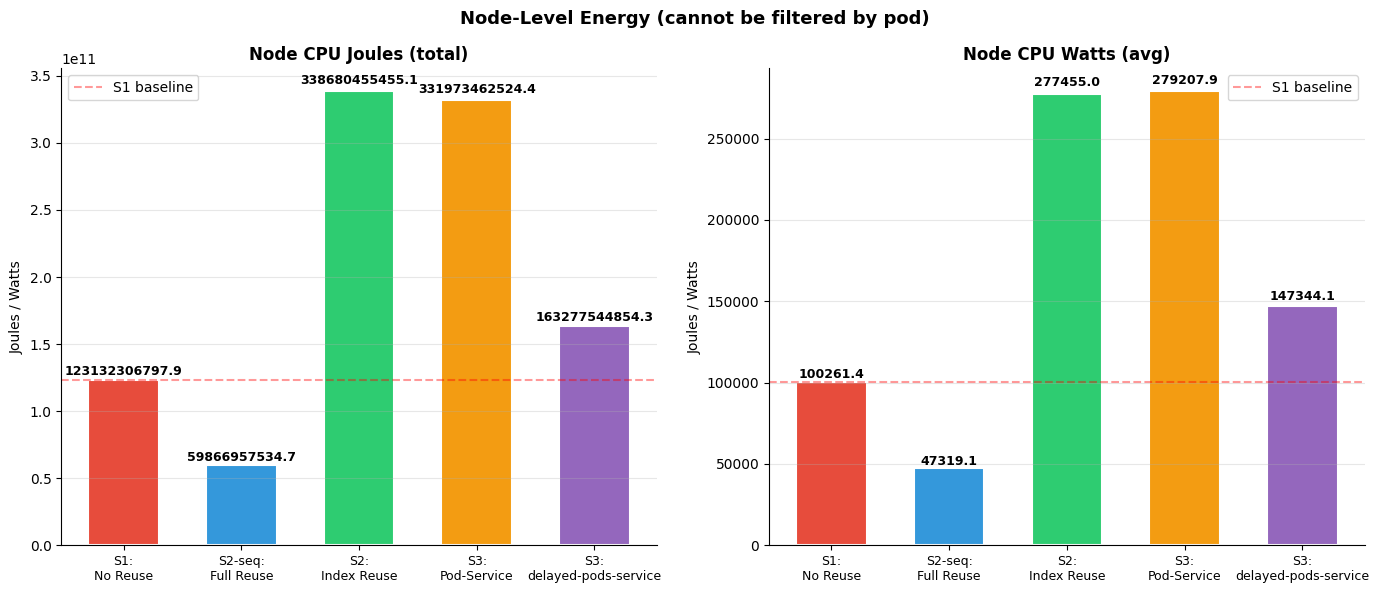

All 11 plots saved to /tmp/plot*.png


In [44]:
# ── Plot 11: Node-Level Energy ────────────────────────────────────────
# Node metrics cannot be filtered by pod — shown as-is with note

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Node-Level Energy (cannot be filtered by pod)',
             fontsize=13, fontweight='bold')

for ax, (metric, title) in zip(axes, [
    ('kepler_node_cpu_power_raw', 'Node CPU Joules (total)'),
    ('kepler_node_cpu_power_sum', 'Node CPU Watts (avg)'),
]):
    values, labels, colors = [], [], []
    for exp_label, exp_dir in EXPERIMENTS.items():
        df = load_metric(exp_dir, metric)
        val = 0
        if df is not None and not df.empty:
            val_col = get_val_col(df)
            if val_col:
                df[val_col] = pd.to_numeric(df[val_col], errors='coerce').fillna(0)
                val = df[val_col].sum()
        values.append(val)
        labels.append(exp_label.replace(': ', ':\n'))
        colors.append(EXP_COLORS[exp_label])

    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
        ax.legend()
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylabel('Joules / Watts', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot11_node_energy.png', dpi=150, bbox_inches='tight')
plt.show()
print('All 11 plots saved to /tmp/plot*.png')


In [46]:
# Run this in your notebook to diagnose
import pandas as pd
import glob, os


BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Normal_nextflow_rnaseq_U2_podservice_2026_04_14_11_34_34_a5f0c363/data'

# Load the kepler CSV
path = os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv')
df = pd.read_csv(path)

print('Columns:', list(df.columns))
print('Shape:', df.shape)
print()

# Find pod column
pod_col = next((c for c in df.columns if 'pod' in c.lower()), None)
val_col = next((c for c in df.columns if 'joules' in c.lower() or c == 'value'), None)
print(f'Pod col: {pod_col}')
print(f'Val col: {val_col}')
print()

if pod_col and val_col:
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce').fillna(0)
    # Energy per pod name
    summary = df.groupby(pod_col)[val_col].sum().sort_values(ascending=False)
    print('=== Energy per pod ===')
    print(summary.to_string())
    print()
    print(f'Total: {summary.sum():.1f} J')
    print(f'nf-* pods only: {summary[summary.index.str.startswith("nf-")].sum():.1f} J')
    print(f'Service pods: {summary[summary.index.str.contains("service", case=False, na=False)].sum():.1f} J')

Columns: ['timestamp', '__name__', 'app_kubernetes_io_component', 'app_kubernetes_io_managed_by', 'app_kubernetes_io_name', 'app_kubernetes_io_version', 'container_id', 'container_name', 'container_namespace', 'helm_sh_chart', 'instance', 'job', 'mode', 'namespace', 'node', 'pod_name', 'service', 'timestamp.1', 'kepler_pod_cpu_power_joules_raw', 'layer', 'unit', 'treatment']
Shape: (17750, 22)

Pod col: pod_name
Val col: kepler_pod_cpu_power_joules_raw

=== Energy per pod ===
pod_name
nextflow-launcher                                  1.112971e+07
stringtie-service                                  2.898667e+05
featurecounts-service                              1.281433e+05
nf-22cb111befed776081664bf5bd640e77-b396b-nmfkx    4.503121e+04
nf-7e69fa3fc4b00652537108b859e25697-6409e-57wj4    4.046983e+04
nf-5292a1a25a753396de2f0a5e9c030b19-a2de3-jdc67    3.005581e+04
nf-b5a0f2f3ca596e0a4200d9c0a26a7793-ff756-4p4r8    2.224593e+04
nf-eaf3b69e79b6dfa632d21a22ac904c37-436af-kwpvp    1.851270e+0

In [47]:
# Run this in your notebook to diagnose
import pandas as pd
import glob, os


BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Delayed_nextflow_rnaseq_U2_podservice_2026_04_13_22_11_39_19d00f6f/data'

# Load the kepler CSV
path = os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv')
df = pd.read_csv(path)

print('Columns:', list(df.columns))
print('Shape:', df.shape)
print()

# Find pod column
pod_col = next((c for c in df.columns if 'pod' in c.lower()), None)
val_col = next((c for c in df.columns if 'joules' in c.lower() or c == 'value'), None)
print(f'Pod col: {pod_col}')
print(f'Val col: {val_col}')
print()

if pod_col and val_col:
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce').fillna(0)
    # Energy per pod name
    summary = df.groupby(pod_col)[val_col].sum().sort_values(ascending=False)
    print('=== Energy per pod ===')
    print(summary.to_string())
    print()
    print(f'Total: {summary.sum():.1f} J')
    print(f'nf-* pods only: {summary[summary.index.str.startswith("nf-")].sum():.1f} J')
    print(f'Service pods: {summary[summary.index.str.contains("service", case=False, na=False)].sum():.1f} J')

Columns: ['timestamp', '__name__', 'app_kubernetes_io_component', 'app_kubernetes_io_managed_by', 'app_kubernetes_io_name', 'app_kubernetes_io_version', 'container_id', 'container_name', 'container_namespace', 'helm_sh_chart', 'instance', 'job', 'mode', 'namespace', 'node', 'pod_name', 'service', 'timestamp.1', 'kepler_pod_cpu_power_joules_raw', 'layer', 'unit', 'treatment']
Shape: (9812, 22)

Pod col: pod_name
Val col: kepler_pod_cpu_power_joules_raw

=== Energy per pod ===
pod_name
nextflow-launcher                                  4269475.824
stringtie-service                                   109792.155
featurecounts-service                                53816.565
nf-3a564ce56ac74a58603cd91951979d6e-a88b9-rs7nb      36886.539
nf-c42e35b57d5a8016706720c0cdc3b513-d2ef6-qsp2b      26423.757
nf-8b2928c8d4e1e6e0f8b313c619482ea1-ff09a-z7m64      23171.505
nf-353ffda755c609b156df7dd3f0737086-aca35-db4x7      20246.142
nf-24c6fef6011ab7ffb7bb8ad2128b18b2-25945-vx8w2      18969.684
nf-af2e

In [76]:
import pandas as pd
import os

BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Normal_nextflow_rnaseq_U2_podservice_2026_04_14_11_34_34_a5f0c363/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))

# Check timestamp column
print('timestamp dtype:', df['timestamp'].dtype)
print('Sample timestamps:')
print(df['timestamp'].head(3).tolist())

# Try parsing
df['ts_parsed'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
print('Parsed NaT count:', df['ts_parsed'].isna().sum())
print('Parsed sample:', df['ts_parsed'].dropna().head(3).tolist())

# Check nf-* pod timestamps
is_task = df['pod_name'].str.startswith('nf-')
print(f'\nnf-* pods: {is_task.sum()} rows')
print('nf-* timestamp range:')
print(df[is_task]['ts_parsed'].min(), '→', df[is_task]['ts_parsed'].max())

# Check what window would exclude
t_start = df[is_task]['ts_parsed'].min()
t_end   = df[is_task]['ts_parsed'].max()
in_window = (df['ts_parsed'] >= t_start) & (df['ts_parsed'] <= t_end)
print(f'\nRows in window: {in_window.sum()} / {len(df)}')

# Energy breakdown within window
is_launcher = df['pod_name'] == 'nextflow-launcher'
is_service  = df['pod_name'].str.contains('service', case=False, na=False)
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

print(f'\nWithin window:')
print(f'  launcher:  {df[is_launcher & in_window][val].sum():.1f} J')
print(f'  services:  {df[is_service & in_window][val].sum():.1f} J')
print(f'  nf-* pods: {df[is_task & in_window][val].sum():.1f} J')
print(f'  total:     {df[in_window][val].sum():.1f} J')

timestamp dtype: object
Sample timestamps:
['2026-03-31 15:19:16.717000008+00:00', '2026-03-31 15:19:16.717000008+00:00', '2026-03-31 15:33:06.717000008+00:00']
Parsed NaT count: 0
Parsed sample: [Timestamp('2026-03-31 15:19:16.717000008+0000', tz='UTC'), Timestamp('2026-03-31 15:19:16.717000008+0000', tz='UTC'), Timestamp('2026-03-31 15:33:06.717000008+0000', tz='UTC')]

nf-* pods: 1288 rows
nf-* timestamp range:
2026-03-31 15:00:16.717000008+00:00 → 2026-03-31 15:50:06.717000008+00:00

Rows in window: 3688 / 3736

Within window:
  launcher:  41694.3 J
  services:  46307.4 J
  nf-* pods: 201024.1 J
  total:     289025.8 J


In [76]:
import pandas as pd
import os

BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Delayed_nextflow_rnaseq_U2_podservice_2026_04_13_22_11_39_19d00f6f/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))

# Check timestamp column
print('timestamp dtype:', df['timestamp'].dtype)
print('Sample timestamps:')
print(df['timestamp'].head(3).tolist())

# Try parsing
df['ts_parsed'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
print('Parsed NaT count:', df['ts_parsed'].isna().sum())
print('Parsed sample:', df['ts_parsed'].dropna().head(3).tolist())

# Check nf-* pod timestamps
is_task = df['pod_name'].str.startswith('nf-')
print(f'\nnf-* pods: {is_task.sum()} rows')
print('nf-* timestamp range:')
print(df[is_task]['ts_parsed'].min(), '→', df[is_task]['ts_parsed'].max())

# Check what window would exclude
t_start = df[is_task]['ts_parsed'].min()
t_end   = df[is_task]['ts_parsed'].max()
in_window = (df['ts_parsed'] >= t_start) & (df['ts_parsed'] <= t_end)
print(f'\nRows in window: {in_window.sum()} / {len(df)}')

# Energy breakdown within window
is_launcher = df['pod_name'] == 'nextflow-launcher'
is_service  = df['pod_name'].str.contains('service', case=False, na=False)
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

print(f'\nWithin window:')
print(f'  launcher:  {df[is_launcher & in_window][val].sum():.1f} J')
print(f'  services:  {df[is_service & in_window][val].sum():.1f} J')
print(f'  nf-* pods: {df[is_task & in_window][val].sum():.1f} J')
print(f'  total:     {df[in_window][val].sum():.1f} J')

timestamp dtype: object
Sample timestamps:
['2026-03-31 15:19:16.717000008+00:00', '2026-03-31 15:19:16.717000008+00:00', '2026-03-31 15:33:06.717000008+00:00']
Parsed NaT count: 0
Parsed sample: [Timestamp('2026-03-31 15:19:16.717000008+0000', tz='UTC'), Timestamp('2026-03-31 15:19:16.717000008+0000', tz='UTC'), Timestamp('2026-03-31 15:33:06.717000008+0000', tz='UTC')]

nf-* pods: 1288 rows
nf-* timestamp range:
2026-03-31 15:00:16.717000008+00:00 → 2026-03-31 15:50:06.717000008+00:00

Rows in window: 3688 / 3736

Within window:
  launcher:  41694.3 J
  services:  46307.4 J
  nf-* pods: 201024.1 J
  total:     289025.8 J


In [48]:
# Check what timestamps exist in the S3 Kepler data
import pandas as pd
import os

BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Normal_nextflow_rnaseq_U2_podservice_2026_04_14_11_34_34_a5f0c363/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')

print('Full timestamp range in file:')
print(f'  Min: {df["ts"].min()}')
print(f'  Max: {df["ts"].max()}')
print()
print('Unique pod name prefixes:')
print(df['pod_name'].str[:20].value_counts().head(10))
print()
print('All nf-* pod timestamps:')
is_task = df['pod_name'].str.startswith('nf-')
print(df[is_task]['ts'].describe())

Full timestamp range in file:
  Min: 2026-04-14 09:34:34.102999926+00:00
  Max: 2026-04-14 14:09:24.102999926+00:00

Unique pod name prefixes:
pod_name
featurecounts-servic    6600
stringtie-service       3300
nextflow-launcher       3300
nf-22cb111befed77608      62
nf-5292a1a25a753396d      54
nf-7e645bca079d2e4c4      38
nf-59c505a5d63f2ba1c      36
nf-7e69fa3fc4b006525      34
nf-b5a0f2f3ca596e0a4      22
nf-c918e0d4f2d8237fc      22
Name: count, dtype: int64

All nf-* pod timestamps:
count                                   4550
mean     2026-04-14 11:46:35.571131648+00:00
min      2026-04-14 09:35:54.102999926+00:00
25%      2026-04-14 10:35:16.602999808+00:00
50%      2026-04-14 11:37:14.102999808+00:00
75%      2026-04-14 13:05:34.102999808+00:00
max      2026-04-14 14:09:24.102999926+00:00
Name: ts, dtype: object


In [50]:
# Check what timestamps exist in the S3 Kepler data
import pandas as pd
import os

BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Delayed_nextflow_rnaseq_U2_podservice_2026_04_13_22_11_39_19d00f6f/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')

print('Full timestamp range in file:')
print(f'  Min: {df["ts"].min()}')
print(f'  Max: {df["ts"].max()}')
print()
print('Unique pod name prefixes:')
print(df['pod_name'].str[:20].value_counts().head(10))
print()
print('All nf-* pod timestamps:')
is_task = df['pod_name'].str.startswith('nf-')
print(df[is_task]['ts'].describe())

Full timestamp range in file:
  Min: 2026-04-13 20:11:39.986000061+00:00
  Max: 2026-04-13 22:32:49.986000061+00:00

Unique pod name prefixes:
pod_name
featurecounts-servic    2902
nextflow-launcher       1696
stringtie-service       1452
nf-3a564ce56ac74a586      44
nf-c42e35b57d5a80167      38
nf-8b2928c8d4e1e6e0f      24
nf-353ffda755c609b15      22
nf-af2ec094f492b2512      20
nf-753d6c982621137b7      20
nf-00ded0d71c134c7ab      20
Name: count, dtype: int64

All nf-* pod timestamps:
count                                   3762
mean     2026-04-13 21:25:48.444267008+00:00
min      2026-04-13 20:12:59.986000061+00:00
25%      2026-04-13 20:50:39.986000128+00:00
50%      2026-04-13 21:28:09.986000128+00:00
75%      2026-04-13 22:02:19.986000128+00:00
max      2026-04-13 22:32:49.986000061+00:00
Name: ts, dtype: object


In [82]:
# Run this in your notebook to check the new S3 data
import pandas as pd
import os

BASE_PATH = '/home/sm/experiments/data'
S3_DIR = 'Q_nextflow_rnaseq_concurrent_U2_podservice_reuse_2026_03_31_17_00_16_e67fec9b/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

is_task    = df['pod_name'].str.startswith('nf-')
is_service = df['pod_name'].str.contains('service', case=False, na=False)

t_start = df[is_task]['ts'].min()
t_end   = df[is_task]['ts'].max()
in_window = (df['ts'] >= t_start) & (df['ts'] <= t_end)

print(f'Pipeline window: {t_start} → {t_end}')
print(f'Duration: {(t_end - t_start).total_seconds()/60:.1f} minutes')
print()
print('Within window:')
print(f'  nf-* task pods: {df[is_task & in_window][val].sum():.1f} J')
print(f'  service pods:   {df[is_service & in_window][val].sum():.1f} J')
print(f'  launcher:       {df[(df["pod_name"]=="nextflow-launcher") & in_window][val].sum():.1f} J')
print()
print('Top 5 pods by energy (windowed):')
print(df[in_window].groupby('pod_name')[val].sum().sort_values(ascending=False).head(10).to_string())

Pipeline window: 2026-03-31 15:00:16.717000008+00:00 → 2026-03-31 15:50:06.717000008+00:00
Duration: 49.8 minutes

Within window:
  nf-* task pods: 201024.1 J
  service pods:   46307.4 J
  launcher:       41694.3 J

Top 5 pods by energy (windowed):
pod_name
nextflow-launcher                                  41694.312
featurecounts-service                              28271.997
nf-140c9c9b7891eca894b2757dad43cede-e6555-hjwbz    25690.068
nf-eb759f7f3e1f0f6e332d3a049526d0f9-f0092-8n4km    18377.682
stringtie-service                                  18035.418
nf-9e101af08a5919cb4d88bb1864675a24-f08fc-jxlqc    17903.982
nf-b24ec7c2d4e4dd371c137d16e67e716a-3fd5d-tzr2x    13452.360
nf-a04097eba2d34a41c1131a317dba16f8-abbd7-nj2dz    12755.037
nf-333599ec91303a3428b4505cb0a3b41a-5349c-qgfrh    12668.808
nf-105ab8426a9c313b7752cc7d3bfccf80-87741-8n5z9     8847.990


In [15]:
# Run this to see the new breakdown
import pandas as pd, os, glob

BASE_PATH = '/home/sm/experiments/data'
dirs = sorted(glob.glob(os.path.join(BASE_PATH, '*podservice*')))
S3_DIR = [d for d in dirs if '10_12' in d or '10_54' in d]
# or just use your latest dir directly
S3_DIR = 'Q_nextflow_rnaseq_U2_podservice_resourceInc_2026_04_01_12_11_34_4d7391ca/data'

df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

is_task    = df['pod_name'].str.startswith('nf-')
is_service = df['pod_name'].str.contains('service', case=False, na=False)
t_start = df[is_task]['ts'].min()
t_end   = df[is_task]['ts'].max()
in_window = (df['ts'] >= t_start) & (df['ts'] <= t_end)

print(f'Duration: {(t_end-t_start).total_seconds()/60:.1f} min')
print(f'nf-* task pods: {df[is_task & in_window][val].sum():.1f} J')
print(f'service pods:   {df[is_service & in_window][val].sum():.1f} J')
print(f'total S3:       {df[(is_task|is_service) & in_window][val].sum():.1f} J')
print(f'S1 baseline:    164998.5 J')
print(f'gap:            {df[(is_task|is_service) & in_window][val].sum() - 164998.5:.1f} J')

Duration: 41.5 min
nf-* task pods: 174098.9 J
service pods:   18551.7 J
total S3:       192650.7 J
S1 baseline:    164998.5 J
gap:            27652.2 J


In [2]:
S3_DIR = 'Q_nextflow_rnaseq_U4_podservice_2026_04_01_13_58_10_ce54b3aa/data'
df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

is_task    = df['pod_name'].str.startswith('nf-')
is_service = df['pod_name'].str.contains('service', case=False, na=False)
t_start = df[is_task]['ts'].min()
t_end   = df[is_task]['ts'].max()
in_window = (df['ts'] >= t_start) & (df['ts'] <= t_end)

print(f'Duration: {(t_end-t_start).total_seconds()/60:.1f} min')
print(f'nf-* task pods: {df[is_task & in_window][val].sum():.1f} J')
print(f'service pods:   {df[is_service & in_window][val].sum():.1f} J')
print(f'total S3:       {df[(is_task|is_service) & in_window][val].sum():.1f} J')
print(f'S1 (3 users):   249692.7 J')
print(f'gap:            {df[(is_task|is_service) & in_window][val].sum() - 249692.7:.1f} J')

Duration: 67.2 min
nf-* task pods: 245754.4 J
service pods:   107799.5 J
total S3:       353553.9 J
S1 (3 users):   249692.7 J
gap:            103861.2 J


In [2]:
S3_DIR = 'S1_nextflow_rnaseq_U2_podservice_2026_04_02_17_52_44_af5e8592/data'
df = pd.read_csv(os.path.join(BASE_PATH, S3_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

is_task    = df['pod_name'].str.startswith('nf-')
is_service = df['pod_name'].str.contains('service', case=False, na=False)
t_start = df[is_task]['ts'].min()
t_end   = df[is_task]['ts'].max()
in_window = (df['ts'] >= t_start) & (df['ts'] <= t_end)

duration = (t_end - t_start).total_seconds() / 60
task_e   = df[is_task & in_window][val].sum()
svc_e    = df[is_service & in_window][val].sum()
total_s3 = task_e + svc_e

print(f'Duration:       {duration:.1f} min')
print(f'nf-* task pods: {task_e:.1f} J')
print(f'service pods:   {svc_e:.1f} J')
print(f'total S3:       {total_s3:.1f} J')
print(f'S1 baseline:    347911.3 J')
print(f'gap:            {total_s3 - 347911.3:.1f} J')
print(f'task pods vs S1: {task_e - 347911.3:.1f} J')

Duration:       119.0 min
nf-* task pods: 336501.4 J
service pods:   115591.9 J
total S3:       452093.3 J
S1 baseline:    347911.3 J
gap:            104182.0 J
task pods vs S1: -11409.9 J


In [3]:
S1_DIR = 'S1_nextflow_rnaseq_U2_baseline_2026_04_02_23_01_07_3cb9d5ab/data'
df = pd.read_csv(os.path.join(BASE_PATH, S1_DIR, 'kepler_pod_cpu_power_joules_raw.csv'))
df['ts'] = pd.to_datetime(df['timestamp'], utc=True, errors='coerce')
val = 'kepler_pod_cpu_power_joules_raw'
df[val] = pd.to_numeric(df[val], errors='coerce').fillna(0)

is_task = df['pod_name'].str.startswith('nf-')
t_start = df[is_task]['ts'].min()
t_end   = df[is_task]['ts'].max()
in_window = (df['ts'] >= t_start) & (df['ts'] <= t_end)

duration = (t_end - t_start).total_seconds() / 60
print(f'S1 Duration:    {duration:.1f} min')
print(f'S1 task pods:   {df[is_task & in_window][val].sum():.1f} J')

S1 Duration:    105.2 min
S1 task pods:   347911.3 J
